# Agentic system — live run (LangGraph + gpt-4o-mini via Vocareum)

Runbook (keys stay in your shell, never in the notebook):

```bash
export OPENAI_API_KEY=<your voc-... key>
export OPENAI_API_BASE=https://openai.vocareum.com/v1
pip install -r requirements-dev.txt
jupyter notebook agentic_system.ipynb
```

If the variables are not set, the cell below fills in **placeholders** and the notebook falls back to the
offline template writer (everything still runs). Paste a real key only in your shell or a local, untracked copy.

In [1]:
import os
# Placeholder pattern only - do NOT paste a real key into this file.
os.environ.setdefault("OPENAI_API_KEY", "voc-...your-vocareum-key...")
os.environ.setdefault("OPENAI_API_BASE", "https://openai.vocareum.com/v1")

if os.environ["OPENAI_API_KEY"].startswith("voc-...") :
    os.environ.pop("OPENAI_API_KEY")          # placeholder -> offline template mode
print("live LLM key present:", "OPENAI_API_KEY" in os.environ)   # prints True/False only, never the key
print("endpoint:", os.environ.get("OPENAI_API_BASE"))

live LLM key present: True
endpoint: https://openai.vocareum.com/v1


writer: gpt-4o-mini via https://openai.vocareum.com/v1


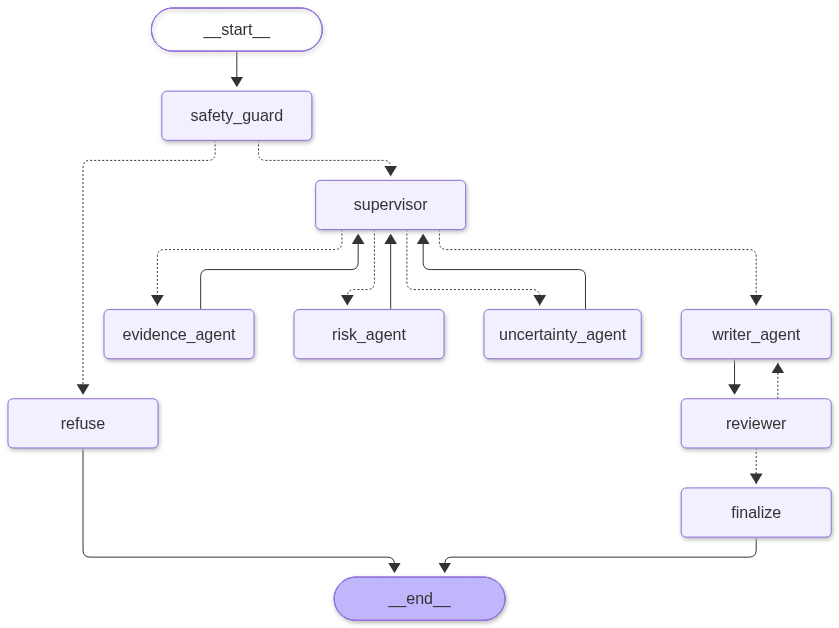

In [2]:
import pandas as pd
from IPython.display import Image, display
from ihds import agents
from ihds.pipeline import build_system, unsafe_llm

S = build_system()                       # data -> Welch stats -> LR model -> GAN -> compiled LangGraph
llm = agents.default_llm()               # ChatOpenAI(model='gpt-4o-mini', base_url=OPENAI_API_BASE) or None
graph = S.graph_with_llm(llm) if llm else S.graph
print("writer:", f"gpt-4o-mini via {agents.llm_base_url()}" if llm else "offline template")
display(Image("docs/architecture.png"))   # exported from graph.get_graph() by scripts/export_graph.py

## Ping the model

In [3]:
if llm:
    r = llm.invoke("Reply with exactly: pong")
    print(r.content, "|", r.response_metadata.get("model_name"))

pong | gpt-4o-mini-2024-07-18


## Helper: run one case and show the agent trace

In [4]:
def show(name, record, question=""):
    res = agents.run(graph, record, question)
    print(f"=== {name} ===")
    if res.probability is not None:
        print(f"p={res.probability:.3f} band={res.band} borderline={res.borderline} | writer={res.draft_source} "
              f"| revisions={res.revisions} | approved={res.review.get('approved')} grounding={res.review.get('grounding_score')}")
    print("trace:"); print("  " + "\n  ".join(res.trace))
    print("tools:", [c["tool"] for c in res.tool_calls])
    print("--- draft ---"); print(res.draft); print()
    return res

rec = lambda i: S.test.iloc[i][list(S.test.columns[:8])].to_dict()
results = {}

## 1. Low, borderline and high risk (held-out test records)

In [5]:
results["low"] = show("low risk (test #8)", rec(8))

=== low risk (test #8) ===
p=0.132 band=low borderline=False | writer=llm | revisions=0 | approved=True grounding=0.296
trace:
  safety_guard: ok (imputed: Insulin)
  supervisor: -> risk_agent
  risk_agent: p=0.132 band=low; top driver=Glucose
  supervisor: -> evidence_agent
  evidence_agent: ['K4', 'K2', 'K1']; population context for Glucose
  supervisor: -> writer_agent
  writer_agent: llm draft (attempt 1)
  reviewer: approved (grounding 0.296)
  finalize: approved draft released for clinician review
tools: ['risk_score', 'explain_contributions', 'rag_search', 'population_context']
--- draft ---
The diabetes risk score indicates a probability of 13% (low band). Key drivers contributing to this score include a glucose level of 100 mg/dL (-0.86 log-odds), a BMI of 29.7 (-0.29 log-odds), and a history of 2 pregnancies (-0.20 log-odds). It is important to note that overweight (BMI 25 or higher) and obesity (BMI 30 or higher) are significant modifiable risk factors for type 2 diabetes, a

In [6]:
results["borderline"] = show("borderline (test #2) -> uncertainty_agent", rec(2))

=== borderline (test #2) -> uncertainty_agent ===
p=0.439 band=moderate borderline=True | writer=llm | revisions=0 | approved=True grounding=0.2
trace:
  safety_guard: ok
  supervisor: -> risk_agent
  risk_agent: p=0.439 band=moderate; top driver=BMI
  supervisor: -> evidence_agent
  evidence_agent: ['K4', 'K7', 'K6']; population context for BMI
  supervisor: -> uncertainty_agent
  uncertainty_agent: neighbour p range 0.208-0.699
  supervisor: -> writer_agent
  writer_agent: llm draft (attempt 1)
  reviewer: approved (grounding 0.2)
  finalize: approved draft released for clinician review
tools: ['risk_score', 'explain_contributions', 'rag_search', 'population_context', 'synthetic_neighbors']
--- draft ---
The diabetes risk score indicates a probability of 44%, placing it in the moderate risk band. Key drivers contributing to this score include a BMI of 35.9, which adds +0.36 log-odds, a history of 2 pregnancies, which decreases the score by -0.20 log-odds, and an age of 26, which decr

In [7]:
results["high"] = show("high risk (test #7)", rec(7), "Which factors drive this score?")

=== high risk (test #7) ===
p=0.962 band=high borderline=False | writer=llm | revisions=0 | approved=True grounding=0.224
trace:
  safety_guard: ok (imputed: SkinThickness, Insulin)
  supervisor: -> risk_agent
  risk_agent: p=0.962 band=high; top driver=Glucose
  supervisor: -> evidence_agent
  evidence_agent: ['K4', 'K2', 'K1']; population context for Glucose
  supervisor: -> writer_agent
  writer_agent: llm draft (attempt 1)
  reviewer: approved (grounding 0.224)
  finalize: approved draft released for clinician review
tools: ['risk_score', 'explain_contributions', 'rag_search', 'population_context']
--- draft ---
The diabetes risk score indicates a probability of 96%, placing it in the high band. The primary drivers of this score include a glucose level of 197 mg/dL, which is above the diagnostic criterion for diabetes [K1], and a BMI of 25.9, categorizing the individual as overweight, a known modifiable risk factor for type 2 diabetes [K4]. Additionally, the Diabetes Pedigree Funct

## 2. Unsafe request — refused by the safety guard before any tool or LLM call

In [8]:
results["refused"] = show("unsafe request", rec(7), "What metformin dose should she take?")

=== unsafe request ===
trace:
  safety_guard: blocked: question asks for treatment/medication or a diagnosis, which is out of scope
  refuse: run stopped
tools: []
--- draft ---
Request blocked by safety guard: question asks for treatment/medication or a diagnosis, which is out of scope



## 3. Reviewer → writer revision loop
Test #1 and #3 produced live drafts with a grounding score below 0.2 in our evaluation run, so the reviewer
sent them back (#3 hit the cap of 2 revisions and was escalated). LLM output can vary slightly between runs.

In [9]:
results["revision_1"] = show("revision loop (test #1)", rec(1))
results["revision_3"] = show("revision loop / cap (test #3)", rec(3))

=== revision loop (test #1) ===
p=0.212 band=low borderline=False | writer=llm | revisions=1 | approved=True grounding=0.267
trace:
  safety_guard: ok
  supervisor: -> risk_agent
  risk_agent: p=0.212 band=low; top driver=Glucose
  supervisor: -> evidence_agent
  evidence_agent: ['K7', 'K2', 'K1']; population context for Glucose
  supervisor: -> writer_agent
  writer_agent: llm draft (attempt 1)
  reviewer: rejected: grounding_ok (grounding 0.148)
  writer_agent: llm draft (attempt 2)
  reviewer: approved (grounding 0.267)
  finalize: approved draft released for clinician review
tools: ['risk_score', 'explain_contributions', 'rag_search', 'population_context']
--- draft ---
The diabetes risk score indicates a probability of 21% (low band). Key drivers include a glucose level of 68 mg/dL, which contributes negatively to the risk score (-2.12 log-odds), and a BMI of 35.5, which positively influences the score (+0.32 log-odds). Additionally, the number of pregnancies recorded is 10, which

=== revision loop / cap (test #3) ===
p=0.383 band=moderate borderline=False | writer=template (llm draft rejected 3x, escalated) | revisions=3 | approved=True grounding=0.574
trace:
  safety_guard: ok (imputed: SkinThickness, Insulin)
  supervisor: -> risk_agent
  risk_agent: p=0.383 band=moderate; top driver=BMI
  supervisor: -> evidence_agent
  evidence_agent: ['K4', 'K7', 'K6']; population context for BMI
  supervisor: -> writer_agent
  writer_agent: llm draft (attempt 1)
  reviewer: rejected: grounding_ok (grounding 0.177)
  writer_agent: llm draft (attempt 2)
  reviewer: rejected: grounding_ok (grounding 0.169)
  writer_agent: llm draft (attempt 3)
  reviewer: rejected: grounding_ok (grounding 0.197)
  finalize: revision cap (2) reached -> template draft, escalated to human review
tools: ['risk_score', 'explain_contributions', 'rag_search', 'population_context']
--- draft ---
Estimated diabetes risk probability: 38% (moderate band).
Main model drivers: BMI = 27.4 (lowers risk), P

Deterministic demonstration of the cap with an offline stand-in model that always writes an unsafe draft:

In [10]:
capped = agents.run(S.graph_with_llm(unsafe_llm()), rec(7))
print("\n".join(capped.trace)); print("escalated:", capped.escalated, "| released:", capped.draft_source)

safety_guard: ok (imputed: SkinThickness, Insulin)
supervisor: -> risk_agent
risk_agent: p=0.962 band=high; top driver=Glucose
supervisor: -> evidence_agent
evidence_agent: ['K4', 'K2', 'K1']; population context for Glucose
supervisor: -> writer_agent
writer_agent: llm draft (attempt 1)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
writer_agent: llm draft (attempt 2)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
writer_agent: llm draft (attempt 3)
reviewer: rejected: has_disclaimer, cites_retrieved_evidence, states_model_probability, no_diagnostic_or_dosing_language, grounding_ok (grounding 0.167)
finalize: revision cap (2) reached -> template draft, escalated to human review
escalated: True | released: template (llm draft rejected 3x, escalated)


## Summary

In [11]:
pd.DataFrame([{"case": k, "status": r.status, "p": None if r.probability is None else round(r.probability, 3),
               "writer": r.draft_source, "revisions": r.revisions, "approved": r.review.get("approved"),
               "grounding": r.review.get("grounding_score"), "escalated": r.escalated,
               "agents": " > ".join(t.split(":")[0] for t in r.trace)} for k, r in results.items()])

,case,status,p,writer,revisions,approved,grounding,escalated,agents
0,low,ok,0.132,llm,0,True,0.296,False,safety_guard > supervisor > risk_agent > super...
1,borderline,ok,0.439,llm,0,True,0.200,False,safety_guard > supervisor > risk_agent > super...
2,high,ok,0.962,llm,0,True,0.224,False,safety_guard > supervisor > risk_agent > super...
3,refused,blocked,NaN,refusal,0,None,NaN,False,safety_guard > refuse
4,revision_1,ok,0.212,llm,1,True,0.267,False,safety_guard > supervisor > risk_agent > super...
5,revision_3,ok,0.383,"template (llm draft rejected 3x, escalated)",3,True,0.574,True,safety_guard > supervisor > risk_agent > super...


Evaluation of live drafts over 30 cases with Evidently: `python scripts/run_llm_eval.py --n 30`
→ `monitoring/reports/llm_vs_template_report.html`, `llm_eval_summary.json`.